In [1]:
import warnings
from statsbombpy.api_client import NoAuthWarning
from socceraction.data.statsbomb import StatsBombLoader
import pandas as pd
from statsbombpy import sb
import numpy as np
import json
import socceraction.spadl as spadl
import torch.nn as nn

warnings.filterwarnings("ignore", category=NoAuthWarning)
warnings.filterwarnings("ignore", message="credentials were not supplied")

pd.set_option("display.max_columns", None)  # Show all columns

In [10]:
train = pd.read_csv("data/train_set.csv", index_col=0)
val = pd.read_csv("data/val_set.csv", index_col=0)

In [ ]:
from typing import Any
import torch
import torch.nn.functional as F


class EventMLP(nn.Module):
    def __init__(self, input_n, output_n, hidden_n):
        super().__init__()
        self.l1 = nn.Linear(input_n, hidden_n)
        self.l2 = nn.Linear(hidden_n, hidden_n)
        self.l3 = nn.Linear(hidden_n, hidden_n)
        self.l4 = nn.Linear(hidden_n, output_n)
        
    def forward(self, x):
        h1 = torch.relu(self.l1(x))
        h2 = torch.relu(self.l2(h1))
        h3 = torch.relu(self.l3(h2))
        
        return self.l4(h3)

In [5]:
def build_dataset(df):
    X = df[
        [
            "is_home",
            "event",
            "start_x",
            "start_y",
            "time_elapsed",
            "duration",
            "result",
            "period_id",
            "minute",
            "second",
            "home_goal_count",
            "away_goal_count",
            "home_red_count",
            "away_red_count",
            "home_yellow_count",
            "away_yellow_count",
            "is_home-1",
            "event-1",
            "start_x-1",
            "start_y-1",
            "time_elapsed-1",
            "duration-1",
            "result-1",
            "is_home-2",
            "event-2",
            "start_x-2",
            "start_y-2",
            "time_elapsed-2",
            "duration-2",
            "result-2",
            "is_home-3",
            "event-3",
            "start_x-3",
            "start_y-3",
            "time_elapsed-3",
            "duration-3",
            "result-3",
            "target",
        ]
    ]
    X = X.drop(["target"], axis=1)
    X = torch.tensor(X.values).float()

    Y = df["target"]
    Y = torch.tensor(Y.values).float()
    Y = F.one_hot(Y.long(), num_classes=107).float()

    return X, Y

In [11]:
Xtr, Ytr = build_dataset(train)
Xval, Yval = build_dataset(val)

In [ ]:
Xtr[:2]

tensor([[-1., -1., -1., -1., -1., -1., -1.,  1.,  0.,  0., -2., -2., -2., -2.,
         -2., -2., -2., -2., -2., -2., -2., -2., -2., -2., -2., -2., -2., -2.,
         -2., -2., -2., -2., -2., -2., -2., -2., -2.]])

In [37]:
g = torch.Generator().manual_seed(42)

n_hidden = 96
vocab_size = len(Ytr[0])

W1 = torch.randn((Xtr.shape[1], n_hidden), generator=g) * (2 ** 0.5)/((Xtr.shape[1])**0.5)
b1 = torch.randn(n_hidden, generator=g) * 0
W2 = torch.randn((n_hidden, n_hidden), generator=g) * (2**0.5) / ((W1.shape[1]) ** 0.5)
b2 = torch.randn(n_hidden, generator=g) * 0
W3 = torch.randn((n_hidden, n_hidden), generator=g) * (2**0.5) / ((W2.shape[1]) ** 0.5)
b3 = torch.randn(n_hidden, generator=g) * 0
W4 = (
    torch.randn((n_hidden, vocab_size), generator=g) * 0.001
)
b4 = torch.randn(vocab_size, generator=g) * 0

parameters = [W1, b1, W2, b2, W3, b3, W4, b4]

for p in parameters:
    p.requires_grad = True

lossi = []

In [ ]:
max_steps = 500000
batch_size = 512
batch_cnt = 100000
train_mode = True


def get_lr(step):
    if step < 500000:
        return 0.1
    elif step < 850000:
        return 0.01
    else:
        return 0.001


for i in range(max_steps):
    if (i % batch_cnt == 0) & train_mode:
        with torch.no_grad():
            h = Xval

            # forward pass
            for j in range(0, len(parameters), 2):
                hpreact = h @ parameters[j] + parameters[j + 1]

                if j < 6:
                    h = torch.relu(hpreact)
                else:
                    h = hpreact

            logits = h

            val_loss = F.binary_cross_entropy_with_logits(logits, Yval)

            lossi.append(val_loss.item())
    
    lr = get_lr(i)
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]

    h = Xb

    # forward pass
    for j in range(0, len(parameters), 2):
        hpreact = h @ parameters[j] + parameters[j + 1]

        if j < len(parameters) - 2:
            h = torch.relu(hpreact)
        else:
            h = hpreact

    logits = h

    loss = F.binary_cross_entropy_with_logits(logits, Yb)

    # backward pass

    for p in parameters:
        p.grad = None

    loss.backward()

    for p in parameters:
        p.data += -lr * p.grad

    

In [ ]:
lossi

[0.7000011801719666,
 0.02551191858947277,
 0.023544693365693092,
 0.02260221168398857,
 0.02131052501499653,
 0.02087351866066456,
 0.02066454105079174,
 0.020630016922950745,
 0.020590055733919144,
 0.0205631572753191]

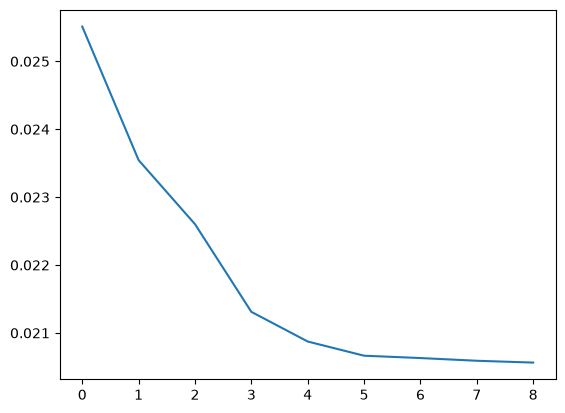

In [42]:
import matplotlib.pyplot as plt

plt.plot(range(len(lossi[1:])), lossi[1:])

In [43]:
checkpoint = {
    "W1": W1,
    "b1": b1,
    "W2": W2,
    "b2": b2,
    "W3": W3,
    "b3": b3,
    "W4": W4,
    "b4": b4,
    "lossi": lossi,
    "max_steps": max_steps,
    "seed": 42,
}
torch.save(checkpoint, "data/mlp_hand_checkpoint.pt")

In [50]:
event_cols = ['is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result']
acc_fields = ['is_home', 'event', 'result']


@torch.no_grad()
def split_accuracy_by_field(split):
    x, y, step = {
        "train": (Xtr, Ytr, train['step'].values),
        "val": (Xval, Yval, val['step'].values),
    }[split]

    step = torch.tensor(step)

    h = x
    for j in range(0, len(parameters), 2):
        hpreact = h @ parameters[j] + parameters[j + 1]

        if j < len(parameters) - 2:
            h = torch.relu(hpreact)
        else:
            h = hpreact

    logits = h
    ix = logits.argmax(dim=1)
    true = y.argmax(dim=1)

    for i, field in enumerate(event_cols):
        mask = step == i
        pred_i, true_i = ix[mask], true[mask]

        if field in acc_fields:
            was_accurate = pred_i == true_i
            accuracy = was_accurate.sum() / len(was_accurate)
            print(split, field, 'accuracy', accuracy.item())
        else:
            pred_val = torch.where(pred_i == 106, torch.tensor(-2), pred_i)
            true_val = torch.where(true_i == 106, torch.tensor(-2), true_i)
            mae = (pred_val - true_val).abs().float().mean()
            print(split, field, 'MAE', mae.item())

In [47]:
#split_accuracy_by_field('train')
split_accuracy_by_field('val')

val is_home accuracy 0.940679669380188
val event accuracy 0.7129665613174438
val start_x MAE 8.8057222366333
val start_y MAE 8.708075523376465
val time_elapsed MAE 1.6751880645751953
val duration MAE 0.8001630306243896
val result accuracy 0.8636126518249512


In [51]:
with open("data/event_masks.json") as f:
    masks = json.load(f)

masks = {
    col: [106 if v == -2 else v for v in vals]
    for col, vals in masks.items()
}

with open("data/category_lookup.json") as f:
    lookup = json.load(f)

lookup = {
    col: {int(k): v for k, v in mapping.items()}
    for col, mapping in lookup.items()
}

In [52]:
@torch.no_grad()
def field_collapse_check(field, split='val'):
    x, y, step = {
        "train": (Xtr, Ytr, train['step'].values),
        "val": (Xval, Yval, val['step'].values),
    }[split]

    step = torch.tensor(step)
    row_mask = step == event_cols.index(field)

    h = x[row_mask]
    for j in range(0, len(parameters), 2):
        hpreact = h @ parameters[j] + parameters[j + 1]

        if j < len(parameters) - 2:
            h = torch.relu(hpreact)
        else:
            h = hpreact

    logits = h

    field_mask = torch.tensor(masks[field])
    n_classes = len(field_mask)

    restricted_logits = logits[:, field_mask]
    pred_pos = restricted_logits.argmax(dim=1)

    pos_lookup = torch.full((107,), -1, dtype=torch.long)
    pos_lookup[field_mask] = torch.arange(n_classes)
    true_pos = pos_lookup[y[row_mask].argmax(dim=1)]

    true_counts = torch.bincount(true_pos, minlength=n_classes).float()
    pred_counts = torch.bincount(pred_pos, minlength=n_classes).float()
    true_dist = true_counts / true_counts.sum()
    pred_dist = pred_counts / pred_counts.sum()

    n_true_used = (true_counts > 0).sum().item()
    n_pred_used = (pred_counts > 0).sum().item()
    tv_dist = 0.5 * (true_dist - pred_dist).abs().sum().item()

    print(f"--- {field} ({split}), n={row_mask.sum().item()} ---")
    print(f"classes predicted: {n_pred_used}/{n_classes}   classes present in data: {n_true_used}/{n_classes}")
    print(f"total variation distance (pred vs true dist): {tv_dist:.4f}")

    order = torch.argsort(true_dist, descending=True)
    for pos in order[:8].tolist():
        code = field_mask[pos].item()
        name = lookup.get(field, {}).get(code, code)
        print(f"  {str(name):>15}  true={true_dist[pos].item()*100:6.2f}%  pred={pred_dist[pos].item()*100:6.2f}%")
    print()


for field in ['is_home', 'event', 'result']:
    field_collapse_check(field, 'val')

--- is_home (val), n=74831 ---
classes predicted: 3/3   classes present in data: 3/3
total variation distance (pred vs true dist): 0.0036
             home  true= 51.76%  pred= 52.11%
             away  true= 48.09%  pred= 47.83%
              106  true=  0.15%  pred=  0.05%

--- event (val), n=74831 ---
classes predicted: 18/24   classes present in data: 24/24
total variation distance (pred vs true dist): 0.1235
             pass  true= 43.05%  pred= 47.18%
          dribble  true= 37.36%  pred= 44.87%
        clearance  true=  2.98%  pred=  3.50%
         throw_in  true=  2.36%  pred=  0.82%
           tackle  true=  2.04%  pred=  2.15%
          take_on  true=  1.76%  pred=  0.00%
     interception  true=  1.75%  pred=  0.87%
        bad_touch  true=  1.54%  pred=  0.01%

--- result (val), n=74831 ---
classes predicted: 6/7   classes present in data: 6/7
total variation distance (pred vs true dist): 0.0821
          success  true= 82.66%  pred= 90.88%
             fail  true= 16.87%

In [53]:
@torch.no_grad()
def field_confusion_matrix(field, split='val'):
    x, y, step = {
        "train": (Xtr, Ytr, train['step'].values),
        "val": (Xval, Yval, val['step'].values),
    }[split]

    step = torch.tensor(step)
    row_mask = step == event_cols.index(field)

    h = x[row_mask]
    for j in range(0, len(parameters), 2):
        hpreact = h @ parameters[j] + parameters[j + 1]

        if j < len(parameters) - 2:
            h = torch.relu(hpreact)
        else:
            h = hpreact

    logits = h

    field_mask = torch.tensor(masks[field])
    n_classes = len(field_mask)

    restricted_logits = logits[:, field_mask]
    pred_pos = restricted_logits.argmax(dim=1)

    pos_lookup = torch.full((107,), -1, dtype=torch.long)
    pos_lookup[field_mask] = torch.arange(n_classes)
    true_pos = pos_lookup[y[row_mask].argmax(dim=1)]

    idx = true_pos * n_classes + pred_pos
    cm = torch.bincount(idx, minlength=n_classes * n_classes).reshape(n_classes, n_classes)

    names = [str(lookup.get(field, {}).get(field_mask[i].item(), field_mask[i].item())) for i in range(n_classes)]
    return pd.DataFrame(cm.numpy(), index=names, columns=names)


def plot_confusion_matrix(cm_df, field, normalize=True):
    cm = cm_df.div(cm_df.sum(axis=1), axis=0).fillna(0) if normalize else cm_df

    fig, ax = plt.subplots(figsize=(max(4, len(cm) * 0.6), max(4, len(cm) * 0.6)))
    im = ax.imshow(cm.values, cmap='Blues')
    ax.set_xticks(range(len(cm.columns)))
    ax.set_xticklabels(cm.columns, rotation=90)
    ax.set_yticks(range(len(cm.index)))
    ax.set_yticklabels(cm.index)
    ax.set_xlabel('predicted')
    ax.set_ylabel('true')
    ax.set_title(f"{field} confusion matrix" + (" (row-normalized)" if normalize else ""))
    fig.colorbar(im, ax=ax)
    fig.tight_layout()

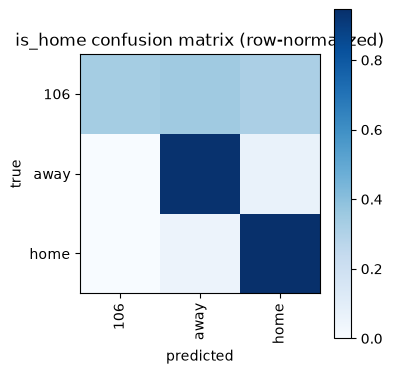

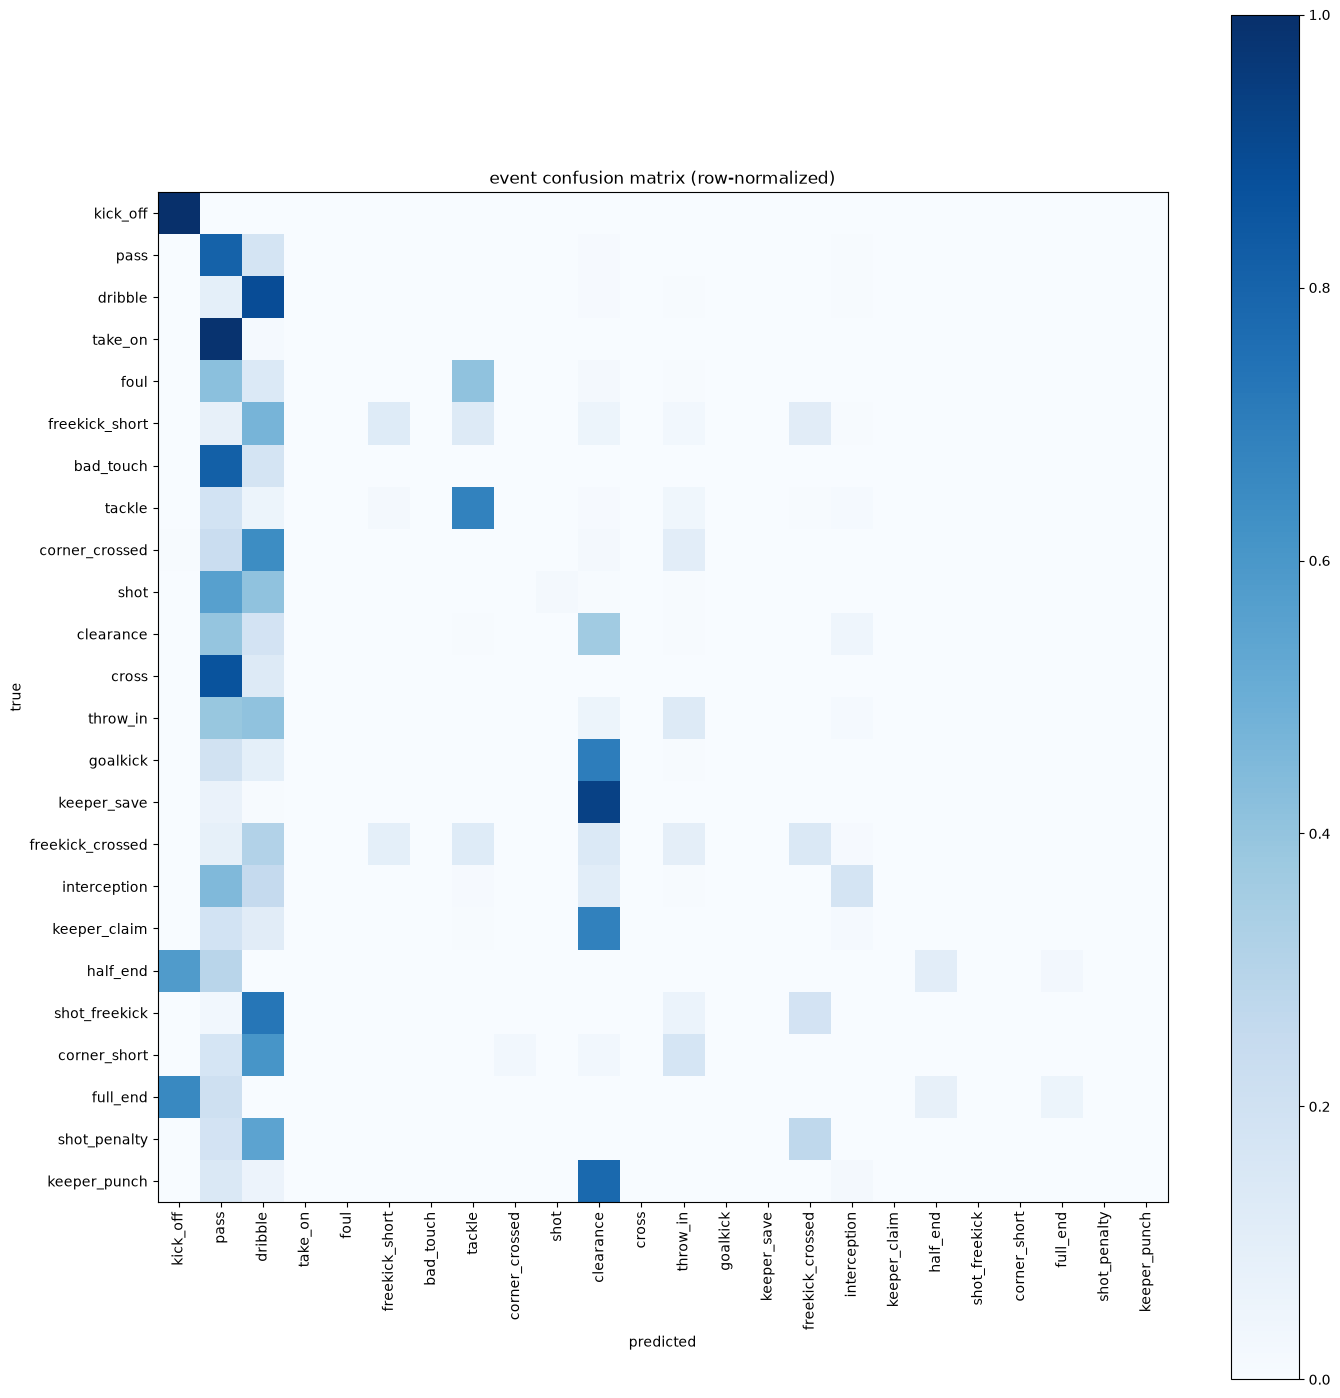

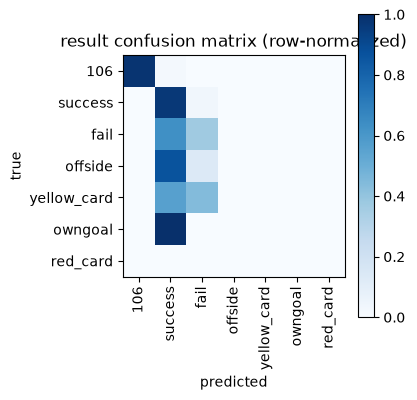

In [54]:
for field in ['is_home', 'event', 'result']:
    cm_df = field_confusion_matrix(field, 'val')
    plot_confusion_matrix(cm_df, field)

In [55]:
def precision_recall_table(cm_df):
    tp = pd.Series(cm_df.values.diagonal(), index=cm_df.index)
    support = cm_df.sum(axis=1)     # true count per class
    predicted = cm_df.sum(axis=0)   # predicted count per class

    recall = (tp / support).fillna(0)
    precision = (tp / predicted).fillna(0)
    f1 = (2 * precision * recall / (precision + recall)).fillna(0)

    return pd.DataFrame({
        "support": support,
        "predicted": predicted,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }).sort_values("support", ascending=False)


event_cm = field_confusion_matrix('event', 'val')
event_pr = precision_recall_table(event_cm)
event_pr

,support,predicted,precision,recall,f1
pass,32212,35307,0.737049,0.807867,0.770835
dribble,27957,33576,0.739516,0.888150,0.807047
clearance,2231,2621,0.309424,0.363514,0.334295
throw_in,1768,615,0.375610,0.130656,0.193873
tackle,1524,1607,0.645302,0.680446,0.662408
take_on,1314,0,0.000000,0.000000,0.000000
interception,1313,651,0.356375,0.176695,0.236253
bad_touch,1149,4,0.000000,0.000000,0.000000
shot,1021,50,0.440000,0.021548,0.041083
foul,906,5,0.400000,0.002208,0.004391


## Baseline: zeroed inputs

Same architecture as the trained model, but every input feature is forced to
zero on every step. With no signal in the input, this model can only fit the
marginal distribution of the target — a floor for "did the real model learn
anything from the input at all." Mirrors the baseline in `mlp.ipynb`, adapted
to the deeper 4-layer architecture.

In [56]:
g_baseline = torch.Generator().manual_seed(42)

n_hidden = 96
vocab_size = len(Ytr[0])

W1_baseline = torch.randn((Xtr.shape[1], n_hidden), generator=g_baseline) * (2 ** 0.5) / ((Xtr.shape[1]) ** 0.5)
b1_baseline = torch.randn(n_hidden, generator=g_baseline) * 0
W2_baseline = torch.randn((n_hidden, n_hidden), generator=g_baseline) * (2 ** 0.5) / ((n_hidden) ** 0.5)
b2_baseline = torch.randn(n_hidden, generator=g_baseline) * 0
W3_baseline = torch.randn((n_hidden, n_hidden), generator=g_baseline) * (2 ** 0.5) / ((n_hidden) ** 0.5)
b3_baseline = torch.randn(n_hidden, generator=g_baseline) * 0
W4_baseline = torch.randn((n_hidden, vocab_size), generator=g_baseline) * 0.001
b4_baseline = torch.randn(vocab_size, generator=g_baseline) * 0

baseline_parameters = [W1_baseline, b1_baseline, W2_baseline, b2_baseline, W3_baseline, b3_baseline, W4_baseline, b4_baseline]

for p in baseline_parameters:
    p.requires_grad = True

baseline_lossi = []

In [57]:
baseline_max_steps = 500000
baseline_batch_size = 512
baseline_batch_cnt = 50000
baseline_lr = 0.1


for i in range(baseline_max_steps):
    if i % baseline_batch_cnt == 0:
        with torch.no_grad():
            h = torch.zeros_like(Xval)

            for j in range(0, len(baseline_parameters), 2):
                hpreact = h @ baseline_parameters[j] + baseline_parameters[j + 1]

                if j < len(baseline_parameters) - 2:
                    h = torch.relu(hpreact)
                else:
                    h = hpreact

            baseline_val_loss = F.binary_cross_entropy_with_logits(h, Yval)

            baseline_lossi.append(baseline_val_loss.item())

    ix = torch.randint(0, Xtr.shape[0], (baseline_batch_size,), generator=g_baseline)
    Xb, Yb = torch.zeros_like(Xtr[ix]), Ytr[ix]

    h = Xb

    for j in range(0, len(baseline_parameters), 2):
        hpreact = h @ baseline_parameters[j] + baseline_parameters[j + 1]

        if j < len(baseline_parameters) - 2:
            h = torch.relu(hpreact)
        else:
            h = hpreact

    logits = h

    loss = F.binary_cross_entropy_with_logits(logits, Yb)

    for p in baseline_parameters:
        p.grad = None

    loss.backward()

    for p in baseline_parameters:
        p.data += -baseline_lr * p.grad

In [10]:
baseline_lossi[0], baseline_lossi[-1]

(0.693147599697113, 0.03604435175657272)

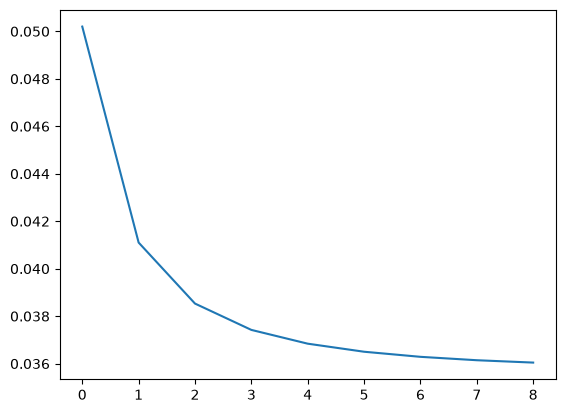

In [11]:
import matplotlib.pyplot as plt

plt.plot(range(len(baseline_lossi[1:])), baseline_lossi[1:])

In [12]:
baseline_checkpoint = {
    "W1": W1_baseline,
    "b1": b1_baseline,
    "W2": W2_baseline,
    "b2": b2_baseline,
    "W3": W3_baseline,
    "b3": b3_baseline,
    "W4": W4_baseline,
    "b4": b4_baseline,
    "lossi": baseline_lossi,
    "max_steps": baseline_max_steps,
    "seed": 42,
}
torch.save(baseline_checkpoint, "data/mlp_hand_baseline_checkpoint.pt")

### Predictions at baseline convergence

Sequentially reveal each field of one all-zero event, same style as the
sampling section of `mlp.ipynb`: feed the (evolving) `start` row through the
baseline model, restrict to each field's valid classes, and take the argmax.
Since the baseline's weights never received gradient except at the final
bias (input is always zero during training), this should converge to
whatever each field's marginally most common value is.

In [58]:
with torch.no_grad():
    start = torch.zeros((1, Xtr.shape[1]))

    for i, field in enumerate(event_cols):
        field_mask = masks[field]

        h = start
        for j in range(0, len(baseline_parameters), 2):
            hpreact = h @ baseline_parameters[j] + baseline_parameters[j + 1]

            if j < len(baseline_parameters) - 2:
                h = torch.relu(hpreact)
            else:
                h = hpreact

        logits = h
        restricted_logits = logits[:, field_mask]

        ix = restricted_logits.argmax(dim=1)
        field_mask_t = torch.tensor(field_mask)
        value = field_mask_t[ix].item()
        value = -2 if value == 106 else value

        start[0, i] = value

        if field in lookup:
            print(field, value, lookup[field][value])
        else:
            print(field, value)

is_home 1 home
event 1 pass
start_x 1
start_y 1
time_elapsed 1
duration 1
result 1 fail


## Sanity check: overfit 2 training rows

Classic training-loop debugging technique: if the forward/backward/update
logic is wired correctly, the network should be able to drive the loss on a
trivial 2-example dataset down to (numerically) zero — if it can't, something
in the implementation is broken, independent of anything going on with the
real ~4M-row dataset. Separate parameters (`*_overfit`), doesn't touch the
trained model or the baseline.

Note: `BCEWithLogits` only reaches loss=0 in the mathematical limit as
logits→±∞, and the gradient shrinks as predictions saturate — so plain SGD
never reaches literal float `0.0` in a practical number of steps (confirmed
empirically: the loss decays roughly like `1/step`, so reaching real float32
zero this way would take on the order of 10^30 steps). What actually matters
for the sanity check — and what we get in a few hundred thousand steps — is a
loss that's numerically indistinguishable from zero, with exact predictions
at near-certain confidence.

In [59]:
g_overfit = torch.Generator().manual_seed(42)

n_hidden = 96
vocab_size = len(Ytr[0])

X_overfit = Xtr[:2]
Y_overfit = Ytr[:2]

W1_overfit = torch.randn((X_overfit.shape[1], n_hidden), generator=g_overfit) * (2 ** 0.5) / ((X_overfit.shape[1]) ** 0.5)
b1_overfit = torch.randn(n_hidden, generator=g_overfit) * 0
W2_overfit = torch.randn((n_hidden, n_hidden), generator=g_overfit) * (2 ** 0.5) / ((n_hidden) ** 0.5)
b2_overfit = torch.randn(n_hidden, generator=g_overfit) * 0
W3_overfit = torch.randn((n_hidden, n_hidden), generator=g_overfit) * (2 ** 0.5) / ((n_hidden) ** 0.5)
b3_overfit = torch.randn(n_hidden, generator=g_overfit) * 0
W4_overfit = torch.randn((n_hidden, vocab_size), generator=g_overfit) * 0.001
b4_overfit = torch.randn(vocab_size, generator=g_overfit) * 0

overfit_parameters = [W1_overfit, b1_overfit, W2_overfit, b2_overfit, W3_overfit, b3_overfit, W4_overfit, b4_overfit]

for p in overfit_parameters:
    p.requires_grad = True

overfit_lossi = []

In [60]:
overfit_max_steps = 300000
overfit_lr = 1.5
overfit_log_cnt = 20000

for i in range(overfit_max_steps):
    h = X_overfit
    for j in range(0, len(overfit_parameters), 2):
        hpreact = h @ overfit_parameters[j] + overfit_parameters[j + 1]

        if j < len(overfit_parameters) - 2:
            h = torch.relu(hpreact)
        else:
            h = hpreact

    logits = h
    loss = F.binary_cross_entropy_with_logits(logits, Y_overfit)

    if i % overfit_log_cnt == 0:
        overfit_lossi.append(loss.item())

    for p in overfit_parameters:
        p.grad = None

    loss.backward()

    for p in overfit_parameters:
        p.data += -overfit_lr * p.grad

overfit_lossi.append(loss.item())

In [61]:
with torch.no_grad():
    h = X_overfit
    for j in range(0, len(overfit_parameters), 2):
        hpreact = h @ overfit_parameters[j] + overfit_parameters[j + 1]

        if j < len(overfit_parameters) - 2:
            h = torch.relu(hpreact)
        else:
            h = hpreact

    logits = h
    probs = F.softmax(logits, dim=1)
    pred = logits.argmax(dim=1)
    true = Y_overfit.argmax(dim=1)

print("loss trajectory:", overfit_lossi)
print("final loss:", overfit_lossi[-1])
print("predicted classes:", pred.tolist(), " true classes:", true.tolist())
print("train accuracy:", (pred == true).float().mean().item())
print("predicted probability assigned to true class:", probs[torch.arange(2), true].tolist())

loss trajectory: [0.6931671500205994, 3.9523484929304686e-07, 1.7787645845146471e-07, 1.0911954007042368e-07, 8.01257584726045e-08, 6.234304095187326e-08, 5.2106059911238845e-08, 3.9090235048888644e-08, 3.605562071129498e-08, 3.3736696991581994e-08, 3.1923871546268856e-08, 2.16486704118779e-08, 2.057048398285133e-08, 1.970470897560972e-08, 1.9039966048239876e-08, 1.83545818543962e-08]
final loss: 1.83545818543962e-08
predicted classes: [106, 0]  true classes: [106, 0]
train accuracy: 1.0
predicted probability assigned to true class: [1.0, 1.0]


## Calibration by event type

Per-class reliability diagrams: one-vs-rest, for each class bin every row's
predicted P(class=c) and check the empirical frequency of class c within
each bin against the diagonal (perfect calibration).

Two different failure shapes show up here: overconfidence (curve sits below
the diagonal at high predicted probability — the dominant classes) vs.
underuse (the model almost never assigns real probability to the class at
all, so points stay stuck near x=0 even where the true rate is meaningfully
higher — the shape for most rare/mid-frequency classes). ECE (weighted mean
|predicted − empirical| across bins) mostly flags the former; mean predicted
probability on the true class flags the latter — a class can have tiny ECE
just because it never gets enough predicted-probability spread to be
"wrong" by much, while still being badly miscalibrated in the sense that
matters (it never expresses real belief in the right answer).

In [62]:
@torch.no_grad()
def field_calibration(field, split='val', n_bins=10):
    x, y, step = {
        "train": (Xtr, Ytr, train['step'].values),
        "val": (Xval, Yval, val['step'].values),
    }[split]

    step = torch.tensor(step)
    row_mask = step == event_cols.index(field)

    h = x[row_mask]
    for j in range(0, len(parameters), 2):
        hpreact = h @ parameters[j] + parameters[j + 1]

        if j < len(parameters) - 2:
            h = torch.relu(hpreact)
        else:
            h = hpreact

    logits = h

    field_mask = torch.tensor(masks[field])
    n_classes = len(field_mask)
    probs = F.softmax(logits[:, field_mask], dim=1).contiguous()

    pos_lookup = torch.full((107,), -1, dtype=torch.long)
    pos_lookup[field_mask] = torch.arange(n_classes)
    true_pos = pos_lookup[y[row_mask].argmax(dim=1)]

    bin_edges = torch.linspace(0, 1, n_bins + 1)

    records = []
    curves = {}
    for pos in range(n_classes):
        code = field_mask[pos].item()
        name = str(lookup.get(field, {}).get(code, code))

        p = probs[:, pos].contiguous()
        is_true = (true_pos == pos).float()

        bin_ids = torch.bucketize(p, bin_edges[1:-1], right=False)
        bpred, bemp, bcnt = [], [], []
        for b in range(n_bins):
            m = bin_ids == b
            c = m.sum().item()
            if c == 0:
                continue
            bpred.append(p[m].mean().item())
            bemp.append(is_true[m].mean().item())
            bcnt.append(c)
        bpred, bemp, bcnt = torch.tensor(bpred), torch.tensor(bemp), torch.tensor(bcnt)
        ece = (bcnt / bcnt.sum() * (bpred - bemp).abs()).sum().item()

        n_true = int(is_true.sum().item())
        mean_prob_when_true = p[is_true == 1].mean().item() if n_true > 0 else float("nan")

        records.append({
            "event": name,
            "n_true": n_true,
            "ece": ece,
            "mean_prob_when_true": mean_prob_when_true,
        })
        curves[name] = (bpred.numpy(), bemp.numpy(), bcnt.numpy())

    summary = pd.DataFrame(records)
    summary["poorly_calibrated"] = (summary["ece"] > 0.02) | (summary["mean_prob_when_true"] < 0.10)
    summary = summary.sort_values("n_true", ascending=False).reset_index(drop=True)

    return summary, curves

In [63]:
def plot_calibration_grid(summary, curves, field):
    n = len(summary)
    ncols = 5
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.6 * nrows))
    axes = axes.flatten()

    for i, row in summary.iterrows():
        ax = axes[i]
        bpred, bemp, bcnt = curves[row["event"]]
        sizes = 20 + 180 * (bcnt / bcnt.max())
        color = "#d62728" if row["poorly_calibrated"] else "#1f77b4"

        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
        ax.plot(bpred, bemp, color=color, alpha=0.4, linewidth=1)
        ax.scatter(bpred, bemp, s=sizes, color=color, alpha=0.8, edgecolor="black", linewidth=0.5)

        ax.set_xlim(-0.02, 1.02)
        ax.set_ylim(-0.02, 1.02)
        ax.set_title(
            f"{row['event']}\nn={row['n_true']}, ECE={row['ece']:.3f}, P(true)={row['mean_prob_when_true']:.2f}",
            fontsize=9, color=color, fontweight="bold" if row["poorly_calibrated"] else "normal",
        )
        ax.tick_params(labelsize=7)

    for j in range(n, len(axes)):
        axes[j].axis("off")

    fig.suptitle(
        f"Calibration (reliability) curves per {field} class — val, sorted by support\n"
        "red = flagged poorly calibrated (ECE>0.02 or mean predicted prob on true class <0.10)",
        fontsize=13,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.96])

,event,n_true,ece,mean_prob_when_true,poorly_calibrated
0,pass,32212,0.091570,0.765176,True
1,dribble,27957,0.049281,0.830530,True
2,clearance,2231,0.005211,0.227294,False
3,throw_in,1768,0.003098,0.155130,False
4,tackle,1524,0.008105,0.408870,False
5,take_on,1314,0.012307,0.018471,True
6,interception,1313,0.002516,0.171846,False
7,bad_touch,1149,0.009980,0.021639,True
8,shot,1021,0.006437,0.066854,True
9,foul,906,0.005419,0.091590,True


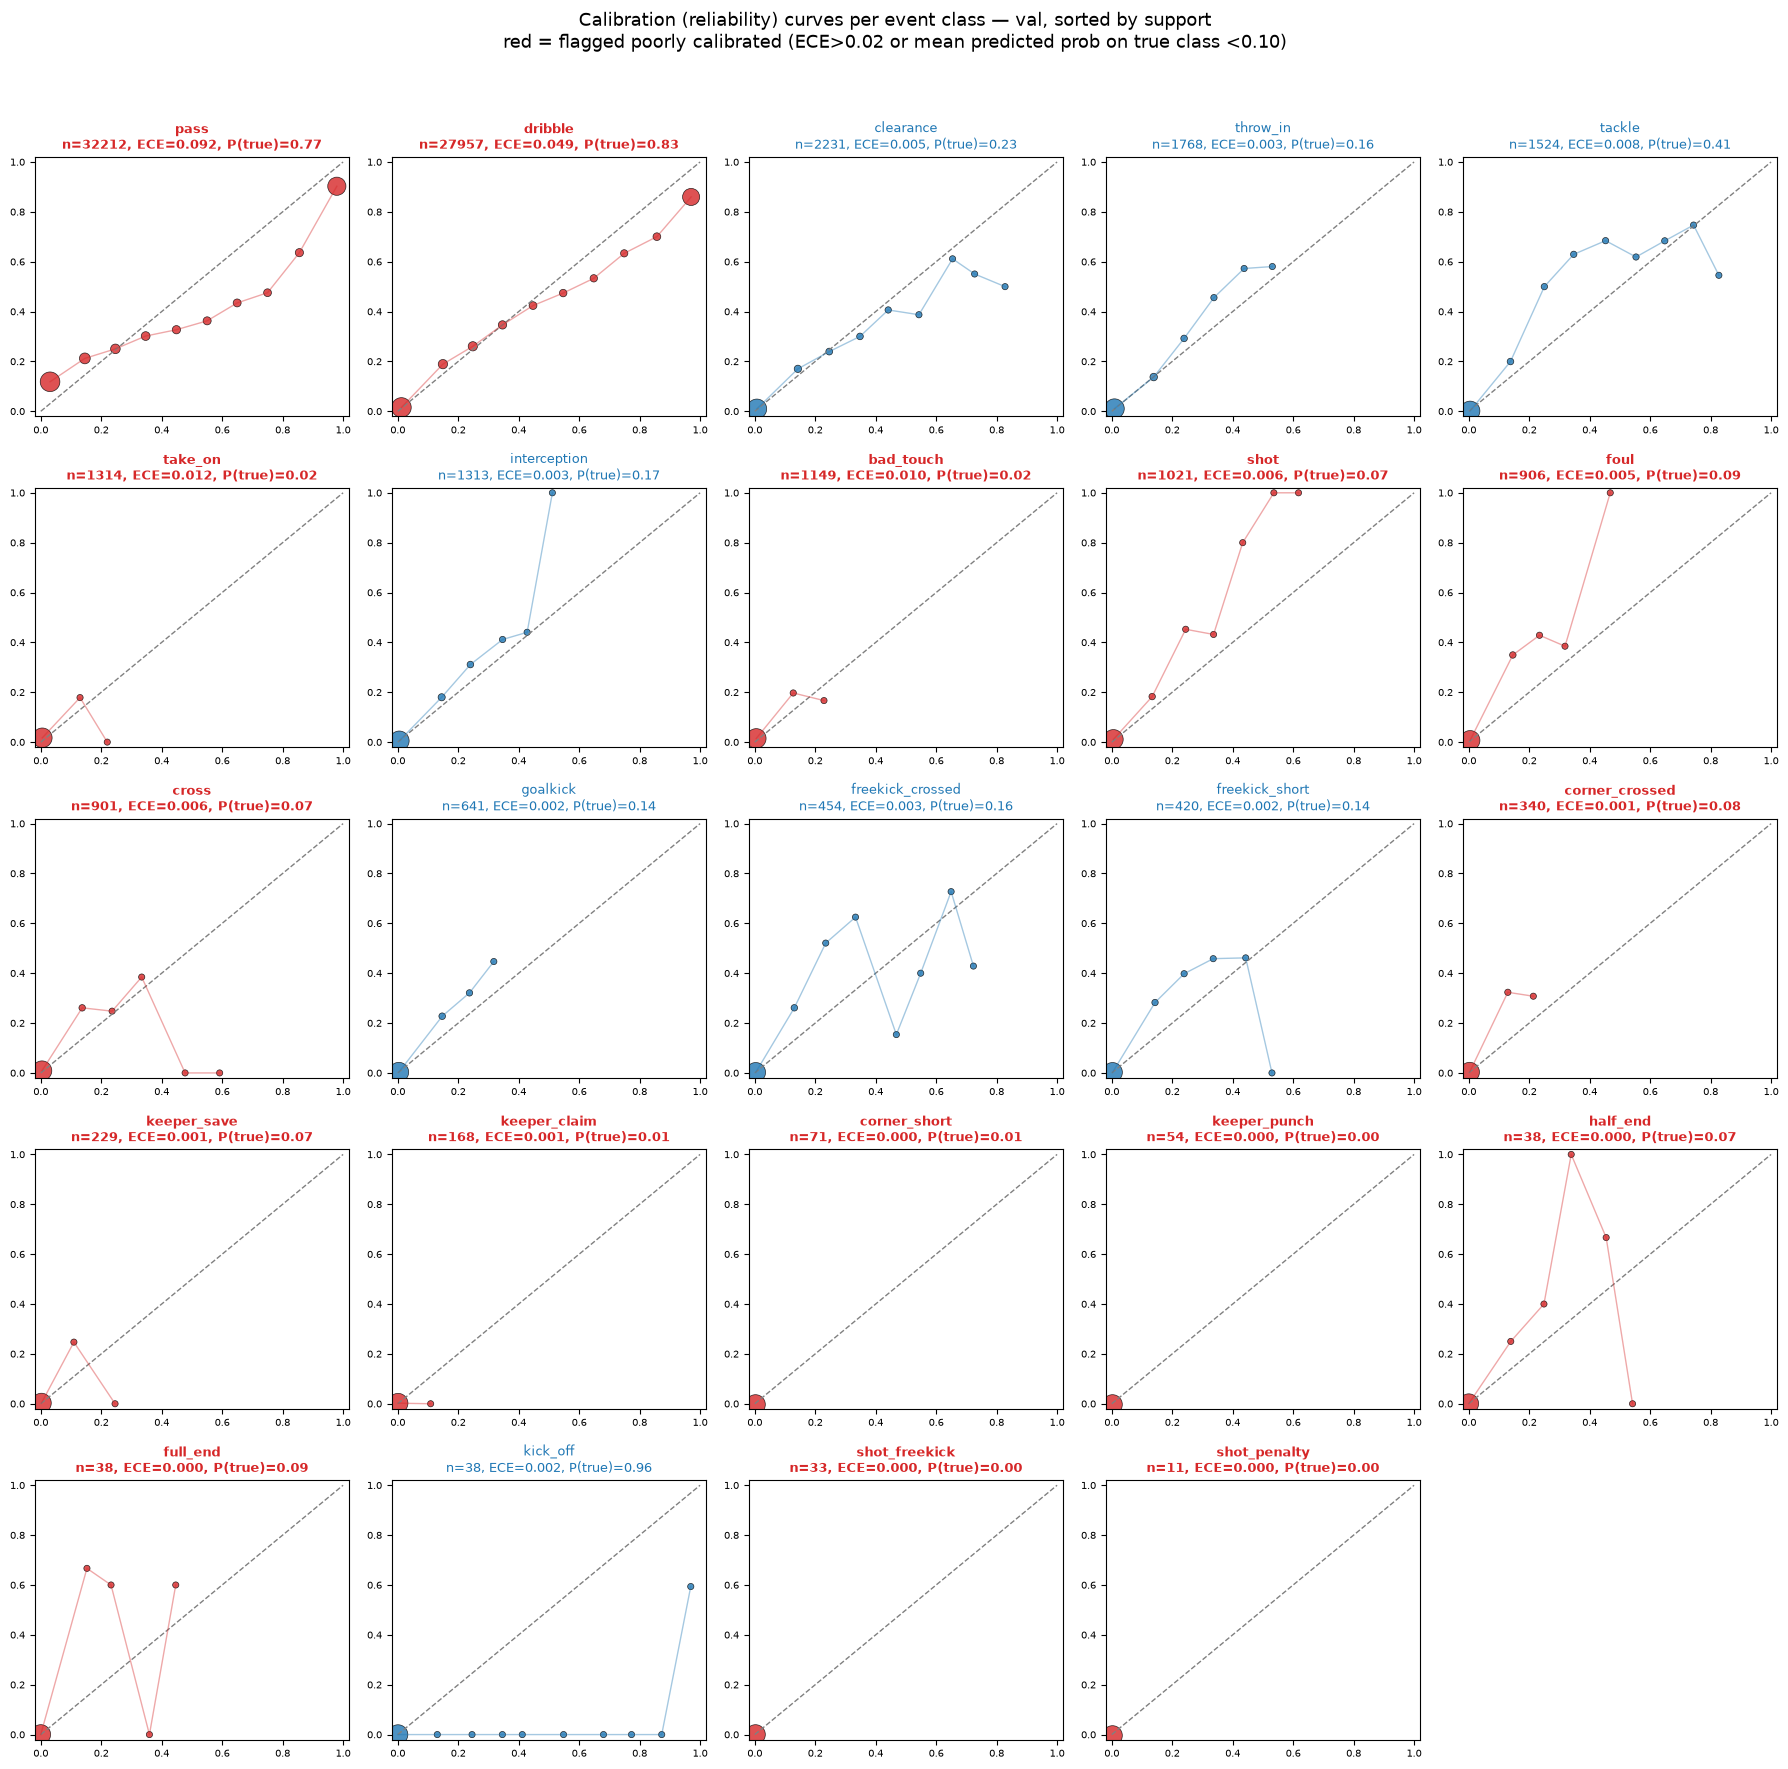

In [64]:
event_calib, event_calib_curves = field_calibration('event', 'val')
plot_calibration_grid(event_calib, event_calib_curves, 'event')
event_calib[["event", "n_true", "ece", "mean_prob_when_true", "poorly_calibrated"]]